# 03 - PhoBERT
- văn bản cột `text_phobert`
- chạy `python -m src.models.train_transformer --model phobert`

In [1]:
import re, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

from src.config import (LABELS, DATA_DIR, MODELS_DIR, RESULTS_METRICS, RESULTS_FIGURES, RESULTS_PREDICTIONS, PREPROCESS_PRESETS, text_col)
print("ROOT =", ROOT)

ROOT = c:\Users\this pc\Downloads\Sourcecode_NLP


In [2]:
MODEL = "phobert"
from src.config import get_transformer_cfg
print("Preset tiền xử lý:", PREPROCESS_PRESETS[MODEL])
display(pd.Series(get_transformer_cfg(MODEL), name="cấu hình"))

d = pd.read_csv(DATA_DIR / "train.csv").sample(5, random_state=7)
display(d[["free_text", text_col(MODEL)]])

Preset tiền xử lý: {'lower': False, 'repeat': True, 'teencode': True, 'emoji': 'text', 'segment': True}


hf_name               vinai/phobert-base-v2
max_len                                 128
batch_size                               16
epochs                                    5
lr                                  0.00002
weight_decay                           0.01
warmup_ratio                            0.1
max_grad_norm                           1.0
patience                                  2
class_weight                           True
class_weight_power                      0.5
Name: cấu hình, dtype: object

,free_text,text_phobert
16538,tôi của 30 năm sau các bạn ạ,tôi của 30 năm sau các bạn ạ
9718,No banh lon dam danh nguoi ta k chac de yen cho may danh,No banh lon dam_danh nguoi ta không chac de_yen cho may_danh
11859,Bảo Tín tối a lên luôn đi,Bảo_Tín tối a lên luôn đi
23806,Cắt bớt đất bán cho trung để trả =)),Cắt bớt đất bán cho trung để trả =))
9640,Ai cũng hiểu rồi chỉ là chưa có ai đứng lên dám làm j thui,Ai cũng hiểu rồi chỉ là chưa có ai đứng lên dám làm gì thui


## 1. Nạp kết quả

In [3]:
metrics_path = RESULTS_METRICS / f"{MODEL}.json"
assert metrics_path.exists(), f"Chưa có kết quả. Hãy chạy phobert"
print("Đã có kết quả:", metrics_path.name)

Đã có kết quả: phobert.json


## 2. Kết quả

phobert: val macro-F1 = 0.6896 | test macro-F1 = 0.6912 | test acc = 0.8660
{'best_epoch': 2, 'n_params': 135000579, 'seconds': 622.5}


,precision,recall,f1,support
BÌNH THƯỜNG,0.9522,0.9150,0.9332,2458.0
XÚC PHẠM,0.4234,0.5771,0.4884,201.0
THÙ GHÉT,0.6304,0.6748,0.6519,326.0


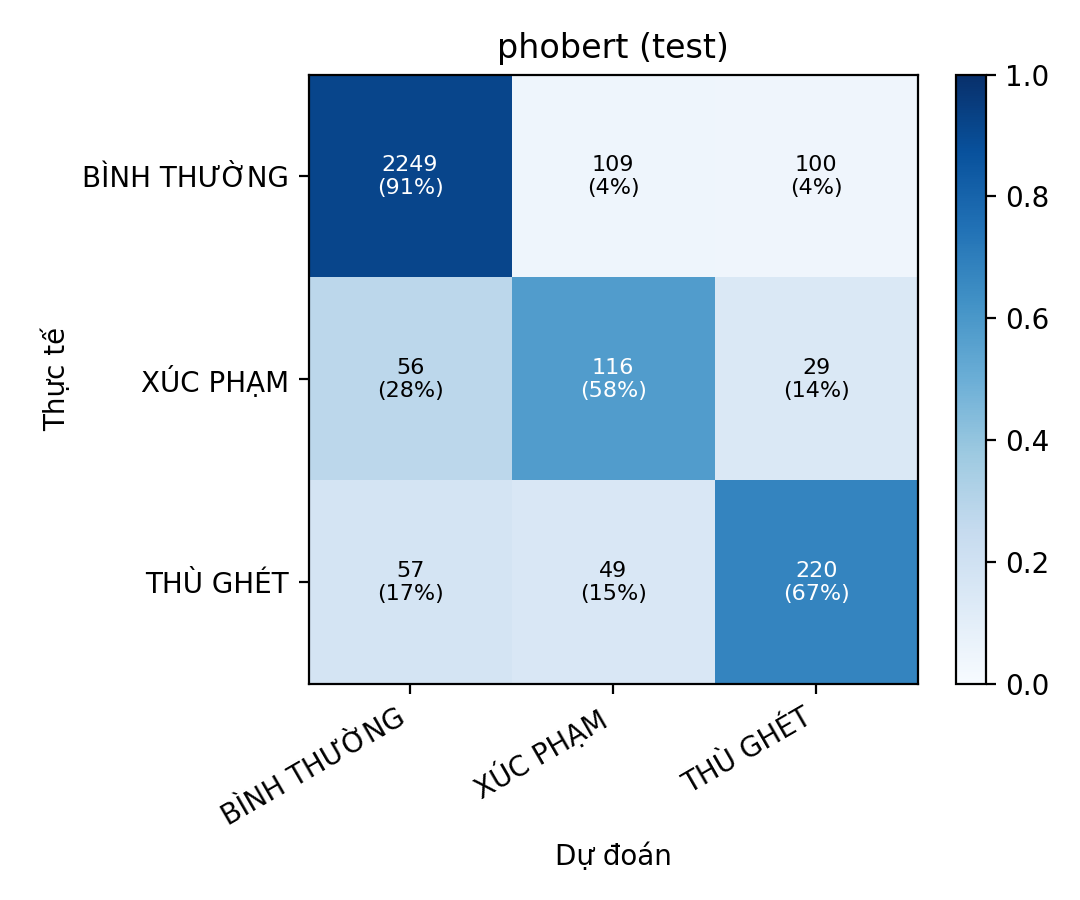

In [4]:
from src.evaluate import show_results
show_results(MODEL)

Mô hình: vinai/phobert-base-v2 | tham số: 135,000,579 | epoch tốt nhất: 2 | thời gian: 622.5s


max_len                   128
batch_size                 16
epochs                      5
lr                    0.00002
weight_decay             0.01
warmup_ratio              0.1
patience                    2
class_weight             True
class_weight_power        0.5
Name: siêu tham số, dtype: object

,val,test
accuracy,0.8671,0.8660
macro_f1,0.6896,0.6912
weighted_f1,0.8738,0.8725


    Theo từng lớp (val)


,precision,recall,f1,support
BÌNH THƯỜNG,0.9554,0.9171,0.9359,2474.0
XÚC PHẠM,0.4291,0.5842,0.4948,202.0
THÙ GHÉT,0.6147,0.6636,0.6382,327.0


    Theo từng lớp (test)


,precision,recall,f1,support
BÌNH THƯỜNG,0.9522,0.9150,0.9332,2458.0
XÚC PHẠM,0.4234,0.5771,0.4884,201.0
THÙ GHÉT,0.6304,0.6748,0.6519,326.0


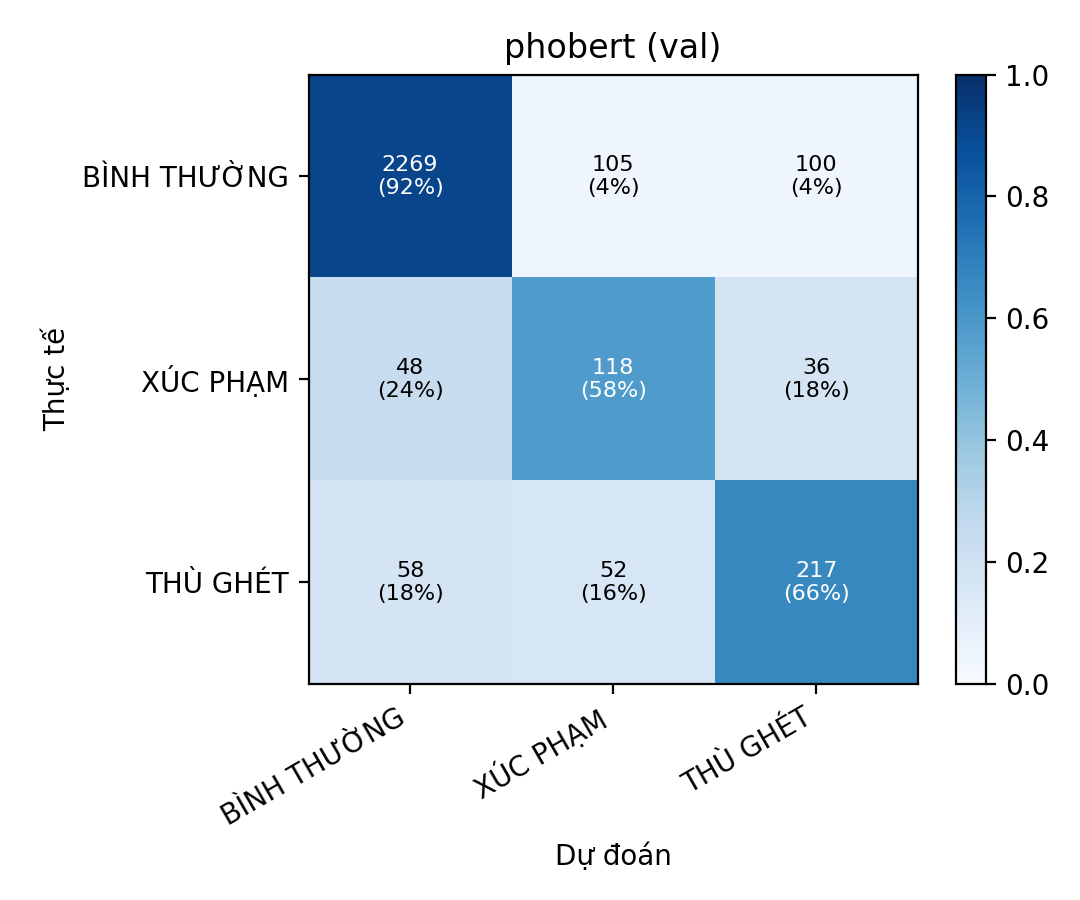

In [5]:
r = json.load(open(metrics_path, encoding="utf-8"))
ex = r["extra"]
print(f"Mô hình: {ex['model']} | tham số: {ex['n_params']:,} | epoch tốt nhất: {ex['best_epoch']} | thời gian: {ex['seconds']}s")
display(pd.Series(ex["hyperparams"], name="siêu tham số"))

overall = pd.DataFrame({s: {k: r[s][k] for k in ("accuracy", "macro_f1", "weighted_f1")} for s in ("val", "test")}).round(4)
display(overall)
for s in ("val", "test"):
    print(f"    Theo từng lớp ({s})")
    display(pd.DataFrame(r[s]["per_class"]).T.round(4))
display(Image(filename=str(RESULTS_FIGURES / f"cm_{MODEL}_val.png")))

## 3. loss và macro-f1 val theo epoch

In [6]:
hist = pd.DataFrame(ex["history"])
display(hist)

fig, ax1 = plt.subplots(figsize=(6.5, 3.6))
ax1.plot(hist.epoch, hist.train_loss, "o-", color="tab:blue")
ax1.set_xlabel("epoch")
ax1.set_ylabel("train loss", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(hist.epoch, hist.val_macro_f1, "s--", color="tab:orange")
ax2.set_ylabel("val macro-F1", color="tab:orange")
ax1.axvline(ex["best_epoch"], color="gray", ls=":")
ax1.set_title(f"{MODEL} – epoch tốt nhất = {ex['best_epoch']}")
plt.tight_layout()
plt.show()

,epoch,train_loss,val_macro_f1
0,1,0.6828,0.6542
1,2,0.4887,0.6896
2,3,0.3653,0.6763
3,4,0.2856,0.6703


C:\Users\this pc\AppData\Local\Temp\ipykernel_22664\1040652445.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 4. So với baseline

In [7]:
bpath = RESULTS_METRICS / "baseline.json"
if bpath.exists():
    rb = json.load(open(bpath, encoding="utf-8"))
    runs = {"baseline": rb, MODEL: r}
    cmp = pd.DataFrame({
        name: {"val macro-F1": x["val"]["macro_f1"], "test macro-F1": x["test"]["macro_f1"], "test acc": x["test"]["accuracy"],
               **{f"test F1 {c}": m["f1"] for c, m in x["test"]["per_class"].items()}}
        for name, x in runs.items()
    }).round(4)
    cmp["chênh lệch (so với baseline)"] = (cmp[MODEL] - cmp["baseline"]).round(4)
    display(cmp)
else:
    print("Chưa có kết quả baseline để so sánh")

,baseline,phobert,chênh lệch (so với baseline)
val macro-F1,0.6771,0.6896,0.0125
test macro-F1,0.6705,0.6912,0.0207
test acc,0.8777,0.8660,-0.0117
test F1 BÌNH THƯỜNG,0.9425,0.9332,-0.0093
test F1 XÚC PHẠM,0.4372,0.4884,0.0512
test F1 THÙ GHÉT,0.6317,0.6519,0.0202


## 5. Độ tin cậy (softmax)

In [8]:
pred = pd.read_csv(RESULTS_PREDICTIONS / f"{MODEL}_test.csv")
print("Độ tin cậy trung bình khi đoán đúng:", round(pred[pred.correct].confidence.mean(), 3))
print("Độ tin cậy trung bình khi đoán sai :", round(pred[~pred.correct].confidence.mean(), 3))
print("Số câu sai có độ tin cậy > 0.8      :", int(((~pred.correct) & (pred.confidence > 0.8)).sum()), "/", int((~pred.correct).sum()))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist([pred[pred.correct].confidence, pred[~pred.correct].confidence], bins=20, label=["đúng", "sai"], stacked=True)
ax.set_xlabel("độ tin cậy")
ax.set_ylabel("số câu")
ax.legend()
ax.set_title(f"{MODEL} – phân bố độ tin cậy trên test")
plt.tight_layout()
plt.show()

Độ tin cậy trung bình khi đoán đúng: 0.939
Độ tin cậy trung bình khi đoán sai : 0.749
Số câu sai có độ tin cậy > 0.8      : 190 / 400


C:\Users\this pc\AppData\Local\Temp\ipykernel_22664\4193493352.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
